# ARI 410/510 Lab 3 Starter Notebook

This notebook gives you the building blocks: downloading the data, viewing a meme, and two pretrained **encoders** (BERT for text, ResNet-18 for images) that turn each meme into vectors. Building, training, and comparing the classifiers is up to you (see the assignment PDF).

**Content note:** this dataset contains hateful and offensive content.

**How to use this:** in Colab, *File → Save a copy in Drive*, and switch to a GPU runtime (*Runtime → Change runtime type*). Run everything on a small subset first (section 5).

> ### ⚠️ Compute your embeddings once, then stop using the images
> The dataset is about 3 GB, and running BERT and ResNet over it is the slowest part of this lab. **You should only do it once.** Section 5 saves your embeddings to your Google Drive. After that, every new Colab session should start at **section 6**, which loads the saved embeddings in a few seconds. No download, no GPU needed.
>
> The only reason to download the images again is to *look at* memes (Part 0, and the 410 "look at the memes" analysis).

## 0. Get the data

The dataset is stored with Git LFS, so this download takes a few minutes. Colab deletes files when your session ends, so this download disappears too.

**If you have already saved your full embeddings (section 5), skip to section 6 instead.** You only need to rerun this cell if you want to look at the images again.

## 1. Load the splits

In [78]:
import os
import pandas as pd

DATA = "hateful_memes"   # folder created by the git clone above
print(sorted(f for f in os.listdir(DATA) if f.endswith(".jsonl")))

def load_split(name):
    df = pd.read_json(os.path.join(DATA, name), lines=True)
    df["path"] = df["img"].apply(lambda p: os.path.join(DATA, p))
    return df

train = load_split("train.jsonl")
dev   = load_split("dev_seen.jsonl")
test  = load_split("test_seen.jsonl")

for name, df in [("train", train), ("dev", dev), ("test", test)]:
    print(f"{name}: {len(df)} memes, {df['label'].mean():.1%} hateful")

train.head()

['dev_seen.jsonl', 'dev_unseen.jsonl', 'test_seen.jsonl', 'test_unseen.jsonl', 'train.jsonl']
train: 8500 memes, 35.5% hateful
dev: 500 memes, 49.4% hateful
test: 1000 memes, 49.0% hateful


,id,img,label,text,path
0,42953,img/42953.png,0,its their character not their color that matters,hateful_memes\img/42953.png
1,23058,img/23058.png,0,don't be afraid to love again everyone is not ...,hateful_memes\img/23058.png
2,13894,img/13894.png,0,putting bows on your pet,hateful_memes\img/13894.png
3,37408,img/37408.png,0,i love everything and everybody! except for sq...,hateful_memes\img/37408.png
4,82403,img/82403.png,0,"everybody loves chocolate chip cookies, even h...",hateful_memes\img/82403.png


## 2. Look at a meme

`show_meme` displays a meme's image with its text and label. Use it for Part 0 of the assignment, and later to look at examples your models get right and wrong.

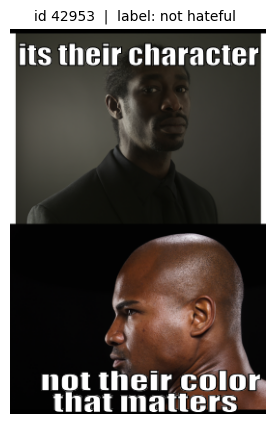

Text: its their character not their color that matters


In [79]:
import matplotlib.pyplot as plt
from PIL import Image

def show_meme(row, note=""):
    """Display one meme. `row` is a row of a split, e.g. dev.iloc[0]."""
    img = Image.open(row["path"]).convert("RGB")
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    label = {0: "not hateful", 1: "hateful"}.get(row.get("label"), "unknown")
    plt.title(f"id {row['id']}  |  label: {label} {note}", fontsize=10)
    plt.show()
    print("Text:", row["text"])

show_meme(train.iloc[0])

## 3. Where embeddings get saved

Computing embeddings is the slow part of this lab. This cell mounts Google Drive so they are saved there and survive the end of your Colab session.

In [80]:
import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/lab3_embeddings"
except ImportError:   # running locally instead of in Colab
    SAVE_DIR = "lab3_embeddings"
os.makedirs(SAVE_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device, "| saving to", SAVE_DIR)

def get_embeddings(name, compute_fn):
    """Load saved embeddings called `name` if they exist; otherwise compute and save them."""
    path = os.path.join(SAVE_DIR, name + ".pt")
    if os.path.exists(path):
        print("loaded", path)
        return torch.load(path)
    emb = compute_fn()
    torch.save(emb, path)
    print("saved", path, tuple(emb.shape))
    return emb

Using cuda | saving to lab3_embeddings


## 4. The pretrained encoders

Neither model below has ever been trained on memes or on hate speech. BERT was trained to predict missing words in books and Wikipedia; ResNet-18 was trained to sort photos into 1,000 ImageNet categories (dogs, cars, mushrooms, ...). We use them **as-is** (no training, `eval()` mode, no gradients) and keep an internal vector instead of their usual output. Your classifiers then learn from those vectors.

### Text: BERT
We keep BERT's vector for the special `[CLS]` token: **768 numbers per text**.

In [81]:
from transformers import AutoTokenizer, AutoModel
device = "cuda"

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased").to(device).eval()

def embed_texts(texts, batch_size=32):
    """List of strings -> tensor of shape [len(texts), 768]."""
    out = []
    for i in range(0, len(texts), batch_size):
        inputs = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                           max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            out.append(bert(**inputs).last_hidden_state[:, 0, :].cpu())
    return torch.cat(out)

print(embed_texts(train["text"].head(4).tolist()).shape)   # expect [4, 768]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1762.43it/s, Materializing param=pooler.dense.weight]                               
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


torch.Size([4, 768])


### Images: ResNet-18
ResNet-18's last layer turns a 512-number vector into scores for the 1,000 ImageNet categories. We replace that layer with `Identity()` (a layer that does nothing), so the model outputs the **512-number vector** instead. Each set of pretrained weights comes with the image preprocessing it expects (resizing, cropping, normalizing), which we apply to every image.

In [82]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=weights)
resnet.fc = torch.nn.Identity()          # remove the final classification layer
resnet = resnet.to(device).eval()
preprocess = weights.transforms()         # the preprocessing these weights expect

def embed_images(paths, batch_size=64):
    """List of image paths -> tensor of shape [len(paths), 512]."""
    out = []
    for i in range(0, len(paths), batch_size):
        # .convert("RGB") handles PNGs with a transparency channel
        batch = torch.stack([preprocess(Image.open(p).convert("RGB"))
                             for p in paths[i:i + batch_size]]).to(device)
        with torch.no_grad():
            out.append(resnet(batch).cpu())
    return torch.cat(out)

print(embed_images(train["path"].head(4).tolist()).shape)   # expect [4, 512]

torch.Size([4, 512])


## 5. Compute and save all the embeddings (once!)

Start with `SUBSET = 200` to make sure everything works end to end. Then set `SUBSET = None` and rerun to embed everything (the image step for the training set takes the longest; a few minutes on a GPU). Because of `get_embeddings`, anything already saved is loaded instead of recomputed.

Note: the file names include the subset size, so subset and full runs don't overwrite each other. This cell also saves each split's ids, texts, and labels as a small CSV, so you can work without the original data files later.

Once this has run with `SUBSET = None`, check that the files above are in your Google Drive. **From now on, you never need to recompute them.**

In [83]:
SUBSET = 200   # set to None for the full dataset

splits = {"train": train, "dev": dev, "test": test}
if SUBSET is not None:
    splits = {name: df.head(SUBSET) for name, df in splits.items()}
tag = "all" if SUBSET is None else str(SUBSET)

X_text, X_image, y = {}, {}, {}
for name, df in splits.items():
    X_text[name]  = get_embeddings(f"{name}_text_{tag}",  lambda: embed_texts(df["text"].tolist()))
    X_image[name] = get_embeddings(f"{name}_image_{tag}", lambda: embed_images(df["path"].tolist()))
    y[name] = torch.tensor(df["label"].values)
    df[["id", "text", "label"]].to_csv(os.path.join(SAVE_DIR, f"{name}_meta_{tag}.csv"), index=False)

for name in splits:
    print(name, tuple(X_text[name].shape), tuple(X_image[name].shape), tuple(y[name].shape))
print("Saved to", SAVE_DIR, ":", sorted(os.listdir(SAVE_DIR)))

loaded lab3_embeddings\train_text_200.pt
loaded lab3_embeddings\train_image_200.pt
loaded lab3_embeddings\dev_text_200.pt
loaded lab3_embeddings\dev_image_200.pt
loaded lab3_embeddings\test_text_200.pt
loaded lab3_embeddings\test_image_200.pt
train (200, 768) (200, 512) (200,)
dev (200, 768) (200, 512) (200,)
test (200, 768) (200, 512) (200,)
Saved to lab3_embeddings : ['dev_image_200.pt', 'dev_image_all.pt', 'dev_meta_200.csv', 'dev_meta_all.csv', 'dev_text_200.pt', 'dev_text_all.pt', 'test_image_200.pt', 'test_image_all.pt', 'test_meta_200.csv', 'test_meta_all.csv', 'test_text_200.pt', 'test_text_all.pt', 'train_image_200.pt', 'train_image_all.pt', 'train_meta_200.csv', 'train_meta_all.csv', 'train_text_200.pt', 'train_text_all.pt']


## 6. Starting a new session? Load your saved embeddings here

Once section 5 has run on the full dataset, start every new Colab session **here** instead of at the top. This cell only reads the files saved in your Google Drive: no dataset download, no BERT or ResNet, and no GPU needed.

In [84]:
import os, torch, pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/lab3_embeddings"
except ImportError:
    SAVE_DIR = "lab3_embeddings"

tag = "all"   # use "200" to load the subset instead
X_text, X_image, y, meta = {}, {}, {}, {}
for name in ["train", "dev", "test"]:
    X_text[name]  = torch.load(os.path.join(SAVE_DIR, f"{name}_text_{tag}.pt"))
    X_image[name] = torch.load(os.path.join(SAVE_DIR, f"{name}_image_{tag}.pt"))
    meta[name]    = pd.read_csv(os.path.join(SAVE_DIR, f"{name}_meta_{tag}.csv"))   # id, text, label
    y[name] = torch.tensor(meta[name]["label"].values)
    print(name, tuple(X_text[name].shape), tuple(X_image[name].shape), tuple(y[name].shape))

train (6744, 768) (6744, 512) (6744,)
dev (398, 768) (398, 512) (398,)
test (815, 768) (815, 512) (815,)


## 7. Your turn

You now have, for each split (`"train"`, `"dev"`, `"test"`):
- `X_text[split]`: BERT vectors, shape `[n, 768]`
- `X_image[split]`: ResNet vectors, shape `[n, 512]`
- `y[split]`: labels (1 = hateful, 0 = not hateful)

The rows line up: row *i* of each tensor is the same meme (and, if you loaded from section 6, the same row of `meta[split]`, so you can look up a meme's id and text). Next steps (see the assignment for details): build the classifier, run the sanity checks, train text-only and image-only models, then early and late fusion, and compare.

Keep your work log going as you work (see the Reflection section of the assignment).

ARI 510
Before running Part 3, write down which modality you expect to be more useful on its
own, and whether (and by how much) you expect fusion to help. Explain your reasoning

    For the initial part of the experiment where we are training on either the text, or the images, I fully expect the model that trains on text to be more successful in identifying hateful versus non hateful memes. Text itself can be very direct in my opinion, words themselves have meaning and definition first and inherit context afterwards. An image on the other hand has no definition, it is inherently contextual first and defined afterwards. In summary I believe there is more value to be found in text around the context 
    I expect fusion to significantly help the results of a trained classifier as opposed to either training the classifier on just text or just images. The range of explanations as to why an image is hateful is so immensely broad that you almost absolutely need the text as context to classify it correctly. The same, maybe less so goes for text classifcation. Some text is so ambiguous or has so much innuendo that without the context of the picture it would be very difficult for it to classify. I believe the Fusion will be able to train twice as long without experiencing the same loss and also achieve F1 scores twice as high.

1. Label distribution. 
How many memes are in each split, and what fraction are hateful? Make a plot.
Is the hateful fraction the same in every split? It isn’t, and that matters for how you read your results
later

In [85]:
print(X_text['train'].shape,
X_text['dev'].shape,
X_text['test'].shape,)

torch.Size([6744, 768]) torch.Size([398, 768]) torch.Size([815, 768])


In [86]:
y_train_df = pd.DataFrame(y['train'])
y_dev_df = pd.DataFrame(y['dev'])
y_test_df = pd.DataFrame(y['test'])

In [87]:
print(
    y_train_df.shape,
    y_dev_df.shape,
    y_test_df.shape
)

(6744, 1) (398, 1) (815, 1)


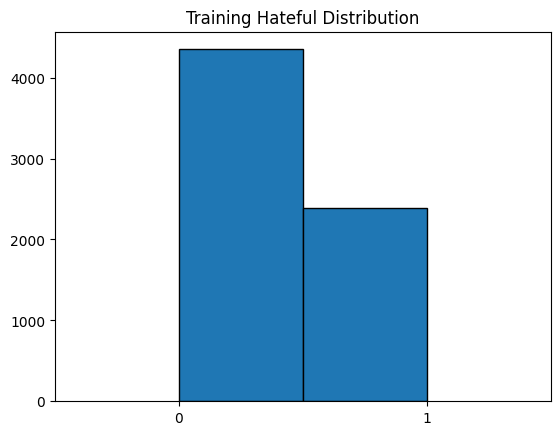

In [88]:
import matplotlib.pyplot as plt

ax = y_train_df.hist(bins=2, edgecolor='black', grid=False)

plt.title('Training Hateful Distribution')

ax_obj = ax.flatten()[0]
ax_obj.set_xticks([0, 1])
ax_obj.set_xlim(-0.5, 1.5)

plt.show()

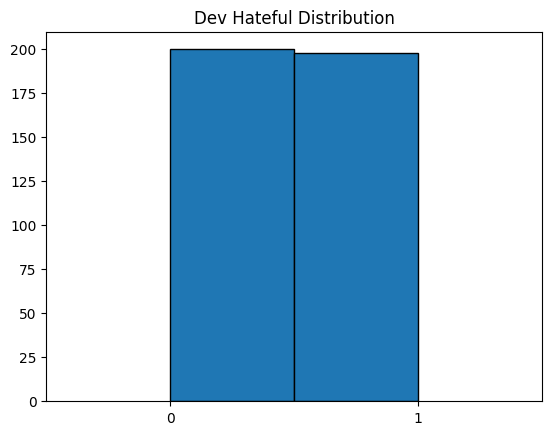

In [89]:
ax = y_dev_df.hist(bins=2, edgecolor='black', grid=False)

plt.title('Dev Hateful Distribution')

ax_obj = ax.flatten()[0]
ax_obj.set_xticks([0, 1])
ax_obj.set_xlim(-0.5, 1.5)

plt.show()

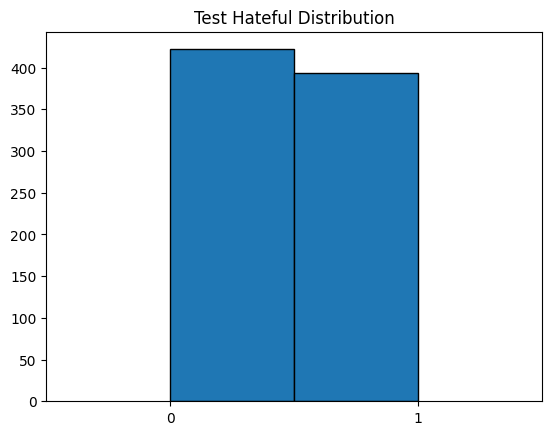

In [90]:
ax = y_test_df.hist(bins=2, edgecolor='black', grid=False)

plt.title('Test Hateful Distribution')

ax_obj = ax.flatten()[0]
ax_obj.set_xticks([0, 1])
ax_obj.set_xlim(-0.5, 1.5)

plt.show()

    In the training split there are 6744 memes, dev split has 398, and the test split has 815. the training split is roughly 2 to one hateful and not hateful while both dev and test are nearly 1 to one Hatful to non hateful.

2. Look at examples.
Look at examples. Look through at least 10 memes from the training set (the starter notebook’s
show meme helper makes this quick). Write down a few things you notice: patterns in the text or
images, what the hateful ones have in common, anything surprising or messy (blurry images, text that
doesn’t match the image, and so on

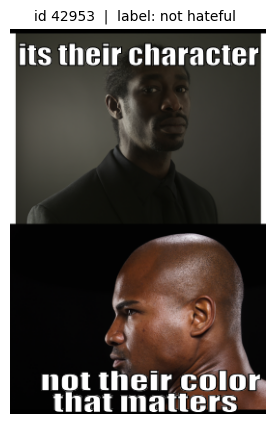

Text: its their character not their color that matters


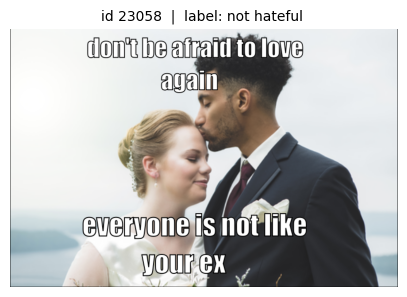

Text: don't be afraid to love again everyone is not like your ex


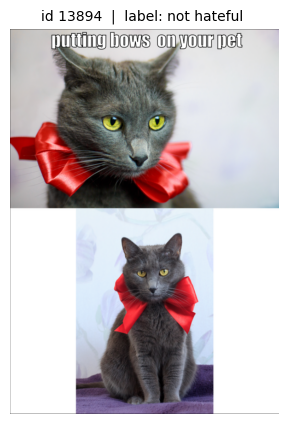

Text: putting bows on your pet


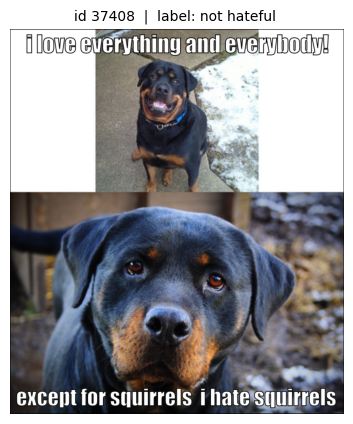

Text: i love everything and everybody! except for squirrels i hate squirrels


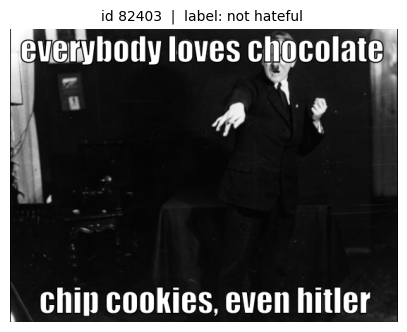

Text: everybody loves chocolate chip cookies, even hitler


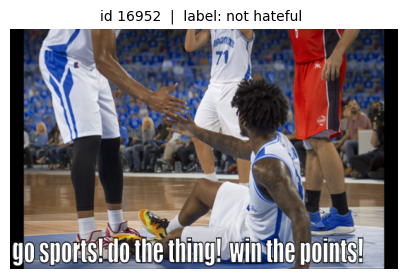

Text: go sports! do the thing! win the points!


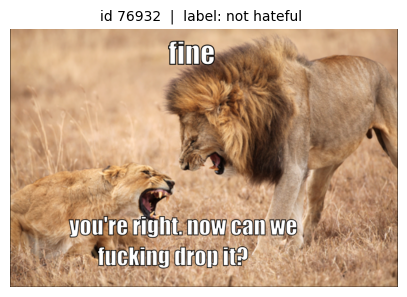

Text: fine you're right. now can we fucking drop it?


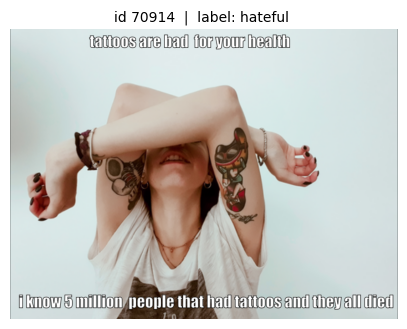

Text: tattoos are bad for your health i know 5 million people that had tattoos and they all died


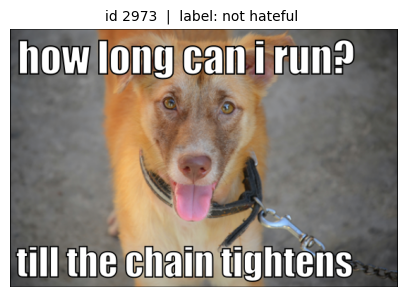

Text: how long can i run? till the chain tightens


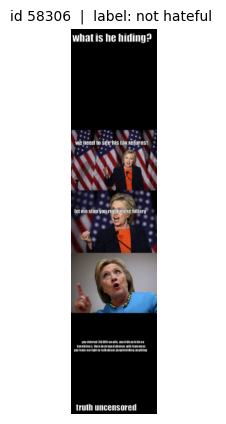

Text: what is he hiding? we need to see his tax returns! let me stop you right there hillary you deleted 30,000 emails, used bleach bit on hard drives, then destroyed phones with hammers you have no right to talk about people hiding anything truth uncensored


In [91]:
for i in range(10):
    show_meme(train.iloc[i])

    It's interesting to see that some of the memes i would classify as hateful are not and vice versa. The last one about polish is obviously hateful, but the one with tattoos to me isn't. The meme with Hillary Clinton is hard to see, it is multiple images laid out into one long image, all the rest are singular images.

3. Be the model.
Pick 10 memes from the dev set and, without looking at the labels, decide for each one
whether it is hateful. Then check the real labels and compute your own accuracy. Which ones did you
get wrong, and why? Did you need both the text and the image to decide? Keep your number: it is a
human baseline to compare your models against.

In [92]:
def show_meme_without_label(row, note=""):
    """Display one meme. `row` is a row of a split, e.g. dev.iloc[0]."""
    img = Image.open(row["path"]).convert("RGB")
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    label = {0: "not hateful", 1: "hateful"}.get(row.get("label"), "unknown")
    plt.title(f"id {row['id']}  |  label:")
    plt.show()
    print("Text:", row["text"])

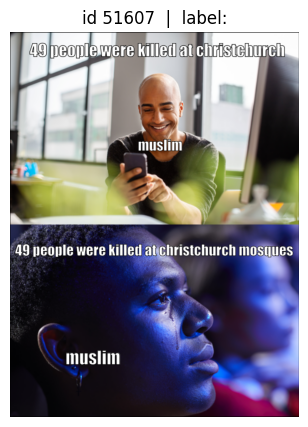

Text: 49 people were killed at christchurch muslim 49 people were killed at christchurch mosques muslim


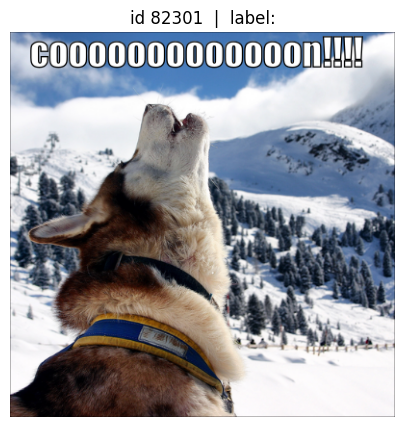

Text: cooooooooooooon!!!!


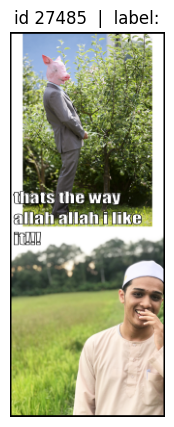

Text: thats the way allah allah i like it!!!


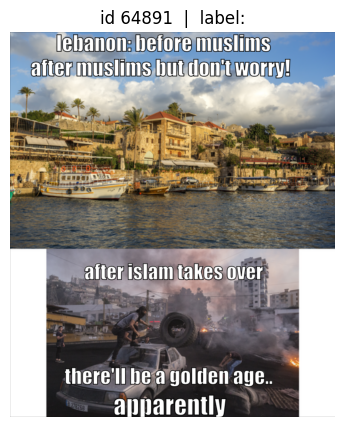

Text: lebanon: before muslims after muslims but don't worry! after islam takes over there'll be a golden age.. apparently


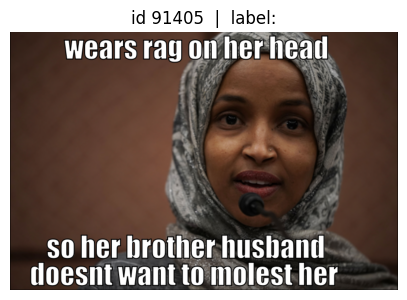

Text: wears rag on her head so her brother husband doesnt want to molest her


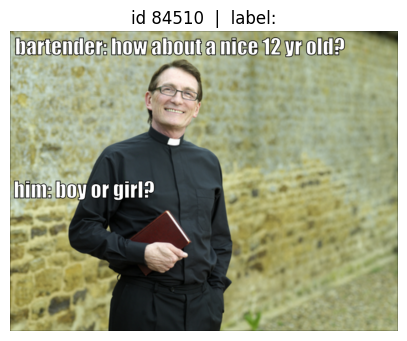

Text: bartender: how about a nice 12 yr old? him: boy or girl?


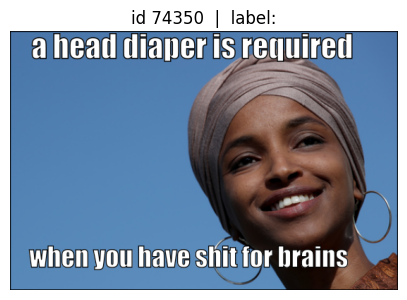

Text: a head diaper is required when you have shit for brains


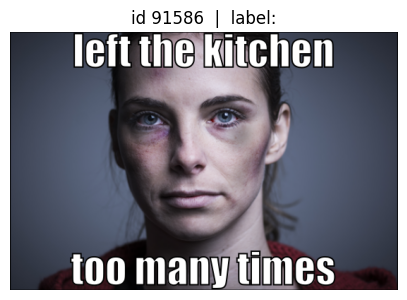

Text: left the kitchen too many times


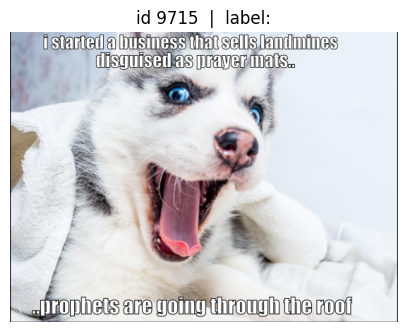

Text: i started a business that sells landmines disguised as prayer mats.. ..prophets are going through the roof


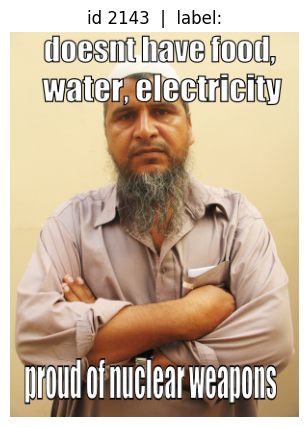

Text: doesnt have food, water, electricity proud of nuclear weapons


In [93]:
import random as rand
rand.seed(47)
for i in range(10):
    show_meme_without_label(dev.iloc[rand.randint(0,100)])

    Hateful; Not Hateful; Hateful; Hateful; Hateful; Hateful; Hateful; Hateful; Hateful; Hateful;

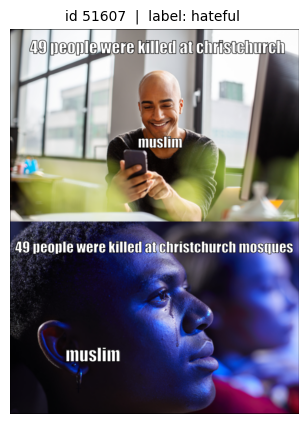

Text: 49 people were killed at christchurch muslim 49 people were killed at christchurch mosques muslim


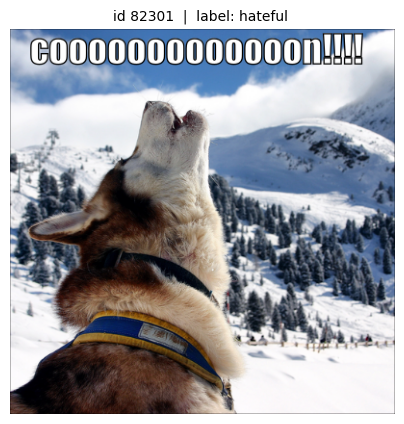

Text: cooooooooooooon!!!!


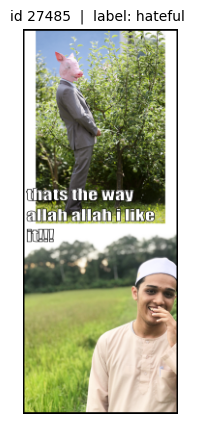

Text: thats the way allah allah i like it!!!


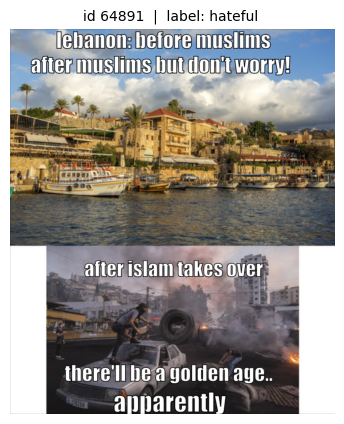

Text: lebanon: before muslims after muslims but don't worry! after islam takes over there'll be a golden age.. apparently


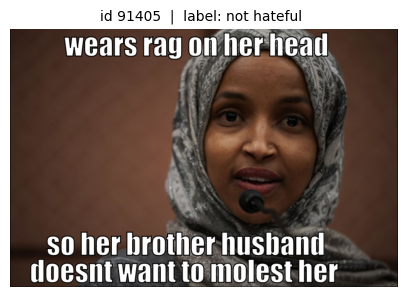

Text: wears rag on her head so her brother husband doesnt want to molest her


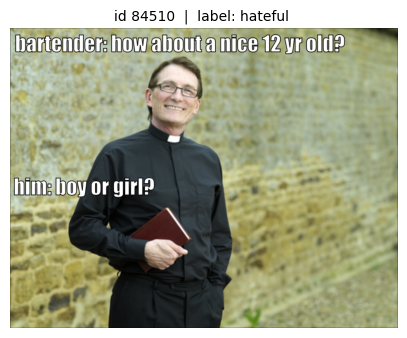

Text: bartender: how about a nice 12 yr old? him: boy or girl?


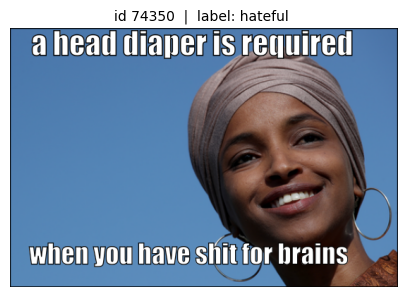

Text: a head diaper is required when you have shit for brains


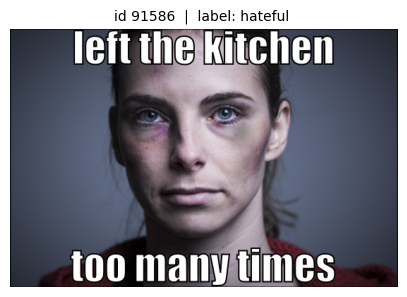

Text: left the kitchen too many times


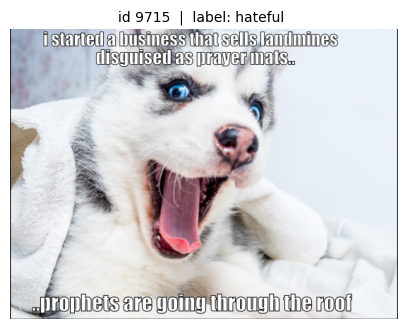

Text: i started a business that sells landmines disguised as prayer mats.. ..prophets are going through the roof


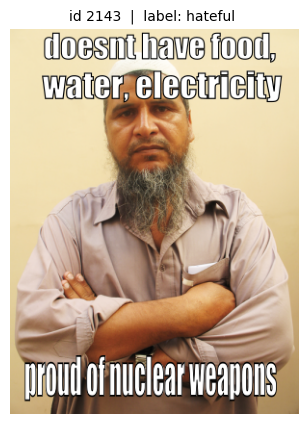

Text: doesnt have food, water, electricity proud of nuclear weapons


In [94]:
rand.seed(47)

for i in range(10):
    show_meme(dev.iloc[rand.randint(0,100)])

    my guess = 1011111111 Labels = 1111011111

    Accuracy = %80

    The wolf howling Goooooon doesn't seem like it would be hateful and im not sure why it is classified that way, possibly because it would be used as a direct insult towards someone. The other miss was the woman wearing the Hijab, that one is obviously hateful to me but it seems it was classified otherwise. Not sure why. I think you do need the text and the image to decide. Most of the time the memes show people in empowered positions and try to undercut the image with the text. For example the woman with the Hiajb looks like she is giving a speech at a conference or something, looking empowered, and the text is in direct contrast to that or avoids the image context entirely. The last image too of the man standing looking fed up could show confidence in his resolve against an issue, instead the text undermines the image again relating it to something the image was most likely never about.

1. ARI 510 Hypothesis. 
Before running Part 3, write down which modality you expect to be more useful on its
own, and whether (and by how much) you expect fusion to help. Explain your reasoning.

    Initially I expect the text classifier to perform better than the image classifier. I believe that text itself is more concrete in the efforts of classifying hateful or non hateful memes. Text itself goes by definition first and only later is context like sarcasm and humor interjected, it will be better at detecting just blatant hate and also subtle interactions between words that indicate hate. Images on the other hand are much more ambiguous by nature. A image is almost the reverse, it is completely ambigous from the start with no definition and is instead solely defined by context. I can understand why a combination of words would indicate hate, but i cannot understand why a combination of pixels aligned in a certain formation would indicate hate.

    I expect fusion to significantly help the results of a trained classifier as opposed to either training the classifier on just text or just images. The range of explanations as to why an image is hateful is so immensely broad that you almost absolutely need the text as context to classify it correctly. The same, maybe less so goes for text classifcation. Some text is so ambiguous or has so much innuendo that without the context of the picture it would be very difficult for it to classify. I believe the Fusion will be able to train twice as long without experiencing the same loss and also achieve F1 scores twice as high.

4.2 Step 2: The classifier
Build a small feedforward neural network that takes an embedding and outputs a single number (a logit) for
“hateful”,

In [95]:
import torch.nn as nn

class Classifier ( nn . Module ) :
    def __init__ ( self , input_dim , hidden_dim ) :
        super () . __init__ ()
        self . fc1 = nn . Linear ( input_dim , hidden_dim )
        self . relu = nn . ReLU ()
        self . fc2 = nn . Linear ( hidden_dim , 1) # one output : the logit for " hateful "
    def forward ( self , x ):
        return self . fc2 ( self . relu ( self . fc1 ( x ) ) )
    
model = Classifier(input_dim =768 , hidden_dim = 100)

4.3 Step 3: Training and evaluation
Train with binary cross-entropy loss, using mini-batches, and evaluate on the dev set with accuracy, pre-
cision, recall, and F1-score. Use the dev set for every decision you make (hidden size, number of epochs,
learning rate, and so on).

1. A dumb baseline. 
Compute all metrics on the dev set for a “model” that always predicts not hateful.
Any real model needs to beat this

In [96]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dummy = DummyClassifier(strategy= 'most_frequent')
dummy.fit(X_text['train'], y['train'])
pred = dummy.predict(X_text['dev'])

acc = accuracy_score(y['dev'], pred)
prec = precision_score(y['dev'], pred, zero_division=0)
rec = recall_score(y['dev'], pred, zero_division=0)
f1 = f1_score(y['dev'], pred, zero_division=0)

print(f"Dev Acc: {acc:.4f} | Dev Prec: {prec:.4f} | Dev Rec: {rec:.4f} | Dev F1: {f1:.4f}")


Dev Acc: 0.5025 | Dev Prec: 0.0000 | Dev Rec: 0.0000 | Dev F1: 0.0000


    because the majority for the dummy is 0 it never guesses a true positive which leads to a divide by 0 scenarion in precision and recall score. This makes the f1 score also collapse to 0. all metrics are undefined besides the accuracy score

Loss at the start. Before any training, compute the loss on a batch. A freshly initialized network
outputs logits near 0 (probabilities near 0.5), so the loss should be close to ln 2 ≈ 0.69. If it is far from
that, something is wrong

In [97]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Instantiate the model, loss function, and optimizer
model = Classifier(input_dim=768, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. Setup your DataLoaders
train_dataset = TensorDataset(X_text['train'], y['train'].float().unsqueeze(1))
dev_dataset = TensorDataset(X_text['dev'], y['dev'].float().unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

# =====================================================================
# SANITY CHECK: Initial Loss Verification
# =====================================================================
model.eval()  # Put in eval mode just to safely check initialization state
with torch.no_grad():
    # Grab a single batch from the training loader
    sanity_x, sanity_y = next(iter(train_loader))
    sanity_logits = model(sanity_x)
    initial_loss = criterion(sanity_logits, sanity_y).item()

print(f"=== Initial Sanity Check ===")
print(f"Expected Initial Loss: ~0.6931 (ln 2)")
print(f"Actual Initial Loss:   {initial_loss:.4f}")
print(f"============================\n")

=== Initial Sanity Check ===
Expected Initial Loss: ~0.6931 (ln 2)
Actual Initial Loss:   0.6622



    It looks like the loss is in range, not too far from expected value

3. Overfit a tiny batch. 
Train on just 20 examples for many epochs. The training loss should go to
nearly 0 and training accuracy to 100%. If your model can’t memorize 20 examples, there is a bug in
your training loop.

In [98]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Instantiate the model, loss function, and optimizer
model = Classifier(input_dim=768, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. Setup your DataLoaders
train_dataset = TensorDataset(X_text['train'], y['train'].float().unsqueeze(1))
dev_dataset = TensorDataset(X_text['dev'], y['dev'].float().unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=20, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

with torch.no_grad():
    # Grab a single batch from the training loader
    overfit_x, overfit_y = next(iter(train_loader))
    overfit_logits = model(overfit_x)
    initial_loss = criterion(overfit_logits, overfit_y).item()

num_epochs = 50

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0

    optimizer.zero_grad()
    
    # Forward pass
    logits = model(overfit_x)
    loss = criterion(logits, overfit_y)
    
    # Backward pass and optimization
    loss.backward()
    optimizer.step()
    
    train_loss += loss.item() * overfit_x.size(0)
    
    total_train_loss = train_loss / len(train_loader.dataset)

    print(f"Epoch {epoch+1}/{num_epochs} -> Train Loss: {total_train_loss:.4f}")



Epoch 1/50 -> Train Loss: 0.0020
Epoch 2/50 -> Train Loss: 0.0017
Epoch 3/50 -> Train Loss: 0.0016
Epoch 4/50 -> Train Loss: 0.0015
Epoch 5/50 -> Train Loss: 0.0014
Epoch 6/50 -> Train Loss: 0.0013
Epoch 7/50 -> Train Loss: 0.0012
Epoch 8/50 -> Train Loss: 0.0011
Epoch 9/50 -> Train Loss: 0.0010
Epoch 10/50 -> Train Loss: 0.0009
Epoch 11/50 -> Train Loss: 0.0008
Epoch 12/50 -> Train Loss: 0.0007
Epoch 13/50 -> Train Loss: 0.0006
Epoch 14/50 -> Train Loss: 0.0006
Epoch 15/50 -> Train Loss: 0.0005
Epoch 16/50 -> Train Loss: 0.0004
Epoch 17/50 -> Train Loss: 0.0004
Epoch 18/50 -> Train Loss: 0.0004
Epoch 19/50 -> Train Loss: 0.0003
Epoch 20/50 -> Train Loss: 0.0003
Epoch 21/50 -> Train Loss: 0.0002
Epoch 22/50 -> Train Loss: 0.0002
Epoch 23/50 -> Train Loss: 0.0002
Epoch 24/50 -> Train Loss: 0.0002
Epoch 25/50 -> Train Loss: 0.0001
Epoch 26/50 -> Train Loss: 0.0001
Epoch 27/50 -> Train Loss: 0.0001
Epoch 28/50 -> Train Loss: 0.0001
Epoch 29/50 -> Train Loss: 0.0001
Epoch 30/50 -> Train Lo

4. Watch the curves. 
When you train on the full training set, record the training loss and the dev loss
after every epoch and plot both. Use the plot to choose the number of epochs: dev loss that starts
going up while training loss keeps going down means the model is overfitting.
Save your trained model so you can run it on the test set later

--> New best Dev Loss achieved (0.7473). Saving checkpoint weights memory.
Epoch 01/50 | Train Loss: 0.5851 | Dev Loss: 0.7473 | Dev F1: 0.3016
Epoch 02/50 | Train Loss: 0.5511 | Dev Loss: 0.8036 | Dev F1: 0.2583
--> New best Dev Loss achieved (0.7260). Saving checkpoint weights memory.
Epoch 03/50 | Train Loss: 0.5392 | Dev Loss: 0.7260 | Dev F1: 0.4028
Epoch 04/50 | Train Loss: 0.5209 | Dev Loss: 0.8240 | Dev F1: 0.2661
Epoch 05/50 | Train Loss: 0.5179 | Dev Loss: 0.8404 | Dev F1: 0.2778
--> New best Dev Loss achieved (0.7061). Saving checkpoint weights memory.
Epoch 06/50 | Train Loss: 0.5034 | Dev Loss: 0.7061 | Dev F1: 0.4702
Epoch 07/50 | Train Loss: 0.4978 | Dev Loss: 0.8197 | Dev F1: 0.2459
Epoch 08/50 | Train Loss: 0.4852 | Dev Loss: 0.7705 | Dev F1: 0.2417
Epoch 09/50 | Train Loss: 0.4729 | Dev Loss: 0.8150 | Dev F1: 0.3271
Epoch 10/50 | Train Loss: 0.4608 | Dev Loss: 0.7778 | Dev F1: 0.5031
Epoch 11/50 | Train Loss: 0.4506 | Dev Loss: 0.8205 | Dev F1: 0.3604
Epoch 12/50 | Tr

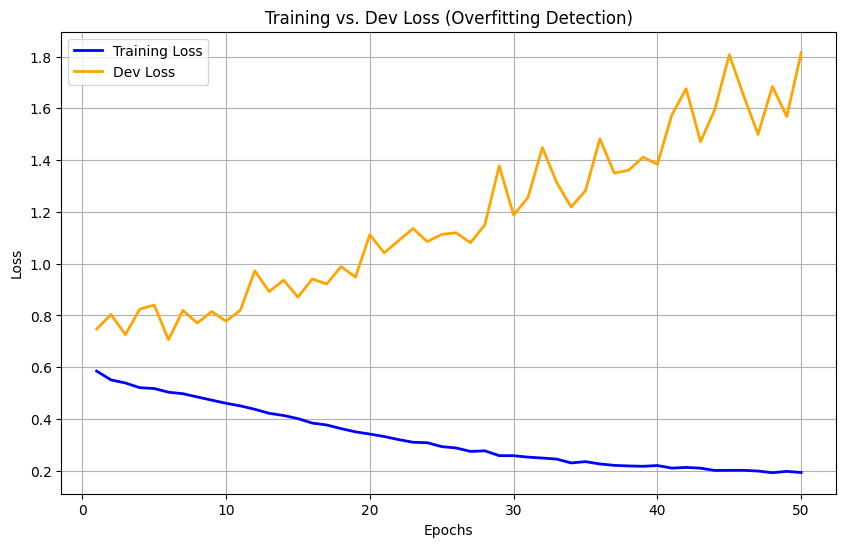

In [99]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import copy

# 1. Instantiate model, loss function, and optimizer
model = Classifier(input_dim=768, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. Setup your DataLoaders
train_dataset = TensorDataset(X_text['train'], y['train'].float().unsqueeze(1))
dev_dataset = TensorDataset(X_text['dev'], y['dev'].float().unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

# Lists to record loss histories for plotting
train_loss_history = []
dev_loss_history = []

# 3. Training and Evaluation Loop
num_epochs = 50  # Increased to give the curves room to show overfitting

# 1. Setup your tracking variables before the loop
best_dev_loss = float('inf')
best_model_weights = None
checkpoint_path = "best__text_classifier_model.pt"

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    total_train_loss = train_loss / len(train_loader.dataset)
    train_loss_history.append(total_train_loss)
    
    # --- EVALUATION PHASE (ON DEV SET) ---
    model.eval()
    dev_loss = 0.0
    dev_preds = []
    dev_true = []
    
    with torch.no_grad():
        for batch_x, batch_y in dev_loader:
            logits = model(batch_x)
            
            # Record dev loss using the same criterion
            loss = criterion(logits, batch_y)
            dev_loss += loss.item() * batch_x.size(0)
            
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).int()
            
            dev_preds.extend(preds.cpu().numpy())
            dev_true.extend(batch_y.cpu().numpy())

    total_dev_loss = dev_loss / len(dev_loader.dataset)

    if total_dev_loss < best_dev_loss:
        best_dev_loss = total_dev_loss
        # Deep copy the weights so they aren't overwritten by subsequent epochs
        best_model_weights = copy.deepcopy(model.state_dict())
        print(f"--> New best Dev Loss achieved ({best_dev_loss:.4f}). Saving checkpoint weights memory.")
            
    total_dev_loss = dev_loss / len(dev_loader.dataset)
    dev_loss_history.append(total_dev_loss)
    
    # Calculate metrics
    acc = accuracy_score(dev_true, dev_preds)
    f1 = f1_score(dev_true, dev_preds, zero_division=0)
    
    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {total_train_loss:.4f} | Dev Loss: {total_dev_loss:.4f} | Dev F1: {f1:.4f}")

if best_model_weights is not None:
    torch.save(best_model_weights, checkpoint_path)
    print(f"\n[SUCCESS] Best model weights saved to '{checkpoint_path}' with Dev Loss: {best_dev_loss:.4f}")

print(f"accuracy: {acc:.2f}, f1: {f1:.2f}")
    
# --- PLOTTING THE CURVES ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss', color='blue', lw=2)
plt.plot(range(1, num_epochs + 1), dev_loss_history, label='Dev Loss', color='orange', lw=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Dev Loss (Overfitting Detection)')
plt.legend()
plt.grid(True)
plt.show()

    It looks like very quickly, only after a 7 epochs, does overfitting start to happen. the dev loss continues to increase although bouncing back and forth. **i experimented with different hidden layer sizes only to achieve the same result. Training epochs until loss may vary**
    

5.1 Step 1: Image embeddings
The starter notebook also sets up a pretrained image model, ResNet-18, as an encoder. ResNet-18 was
trained to sort photos into 1,000 ImageNet categories (dogs, cars, mushrooms, and so on). The notebook
removes its final classification layer, so instead of scores for those 1,000 categories it outputs the 512 numbers
that layer would have used: one vector per image. Read through that part of the notebook. In your report,
explain in a sentence or two why it makes sense to remove the final layer here.

    We want to remove the final layer because we do not want the images classified into what they are i.e. mushroom, dog, etc... Instead we aim to utilize the same vector representation of the image through ResNet-18 by passing it to another model to evaluate whether or not the image is hateful. Borrowing the encoding allows us to "pass" the image to our model and removes the need to train our own.

--> New best Dev Loss achieved (0.6961). Saving checkpoint weights memory.
Epoch 01/50 | Train Loss: 0.6488 | Dev Loss: 0.6961 | Dev F1: 0.5102
Epoch 02/50 | Train Loss: 0.6381 | Dev Loss: 0.8033 | Dev F1: 0.0101
Epoch 03/50 | Train Loss: 0.6314 | Dev Loss: 0.7398 | Dev F1: 0.1667
Epoch 04/50 | Train Loss: 0.6290 | Dev Loss: 0.7749 | Dev F1: 0.1150
Epoch 05/50 | Train Loss: 0.6262 | Dev Loss: 0.7416 | Dev F1: 0.2292
Epoch 06/50 | Train Loss: 0.6239 | Dev Loss: 0.7726 | Dev F1: 0.0654
Epoch 07/50 | Train Loss: 0.6177 | Dev Loss: 0.8195 | Dev F1: 0.0100
Epoch 08/50 | Train Loss: 0.6120 | Dev Loss: 0.7873 | Dev F1: 0.1597
Epoch 09/50 | Train Loss: 0.6049 | Dev Loss: 0.8059 | Dev F1: 0.1086
Epoch 10/50 | Train Loss: 0.6057 | Dev Loss: 0.8246 | Dev F1: 0.0741
Epoch 11/50 | Train Loss: 0.5999 | Dev Loss: 0.8259 | Dev F1: 0.1091
Epoch 12/50 | Train Loss: 0.5913 | Dev Loss: 0.9222 | Dev F1: 0.0818
Epoch 13/50 | Train Loss: 0.5851 | Dev Loss: 0.9250 | Dev F1: 0.0909
Epoch 14/50 | Train Loss: 0.

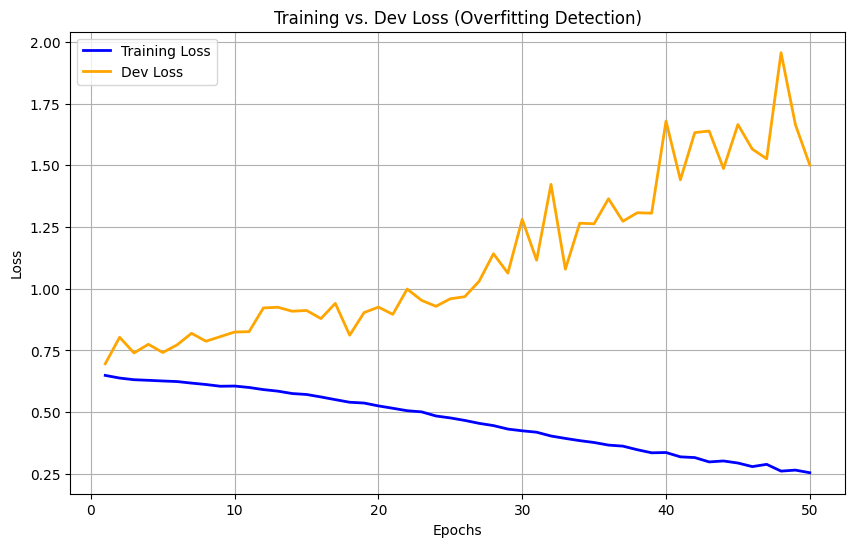

In [100]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import copy

# 1. Instantiate model, loss function, and optimizer
model = Classifier(input_dim=512, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)



# 2. Setup your DataLoaders
train_dataset = TensorDataset(X_image['train'], y['train'].float().unsqueeze(1))
dev_dataset = TensorDataset(X_image['dev'], y['dev'].float().unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

# Lists to record loss histories for plotting
train_loss_history = []
dev_loss_history = []

# 3. Training and Evaluation Loop
num_epochs = 50  # Increased to give the curves room to show overfitting

# 1. Setup your tracking variables before the loop
best_dev_loss = float('inf')
best_model_weights = None
checkpoint_path = "best_image_classifier_model.pt"

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    total_train_loss = train_loss / len(train_loader.dataset)
    train_loss_history.append(total_train_loss)
    
    # --- EVALUATION PHASE (ON DEV SET) ---
    model.eval()
    dev_loss = 0.0
    dev_preds = []
    dev_true = []
    
    with torch.no_grad():
        for batch_x, batch_y in dev_loader:
            logits = model(batch_x)
            
            # Record dev loss using the same criterion
            loss = criterion(logits, batch_y)
            dev_loss += loss.item() * batch_x.size(0)
            
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).int()
            
            dev_preds.extend(preds.cpu().numpy())
            dev_true.extend(batch_y.cpu().numpy())

    total_dev_loss = dev_loss / len(dev_loader.dataset)

    if total_dev_loss < best_dev_loss:
        best_dev_loss = total_dev_loss
        # Deep copy the weights so they aren't overwritten by subsequent epochs
        best_model_weights = copy.deepcopy(model.state_dict())
        print(f"--> New best Dev Loss achieved ({best_dev_loss:.4f}). Saving checkpoint weights memory.")
            
    total_dev_loss = dev_loss / len(dev_loader.dataset)
    dev_loss_history.append(total_dev_loss)
    
    # Calculate metrics
    acc = accuracy_score(dev_true, dev_preds)
    f1 = f1_score(dev_true, dev_preds, zero_division=0)
    
    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {total_train_loss:.4f} | Dev Loss: {total_dev_loss:.4f} | Dev F1: {f1:.4f}")

if best_model_weights is not None:
    torch.save(best_model_weights, checkpoint_path)
    print(f"\n[SUCCESS] Best model weights saved to '{checkpoint_path}' with Dev Loss: {best_dev_loss:.4f}")

print(f"accuracy: {acc:.2f}, f1: {f1:.2f}")
    
# --- PLOTTING THE CURVES ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss', color='blue', lw=2)
plt.plot(range(1, num_epochs + 1), dev_loss_history, label='Dev Loss', color='orange', lw=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Dev Loss (Overfitting Detection)')
plt.legend()
plt.grid(True)
plt.show()

1. Hypothesis. 
Before running Part 3, write down which modality you expect to be more useful on its
own, and whether (and by how much) you expect fusion to help. Explain your reasoning.

    I expect fusion to significantly help the results of a trained classifier as opposed to either training the classifier on just text or just images. The range of explanations as to why an image is hateful is so immensely broad that you almost absolutely need the text as context to classify it correctly. The same, maybe less so goes for text classifcation. Some text is so ambiguous or has so much innuendo that without the context of the picture it would be very difficult for it to classify. I believe the Fusion will be able to train twice as long without experiencing the same loss and also achieve F1 scores twice as high.

Epoch 01/50 | Train Loss: 0.6014 | Dev Loss: 0.7707 | Dev F1: 0.2241
  --> New best Dev Loss achieved (0.7707). Saving checkpoint weights memory.
Epoch 02/50 | Train Loss: 0.5550 | Dev Loss: 0.7592 | Dev F1: 0.3714
  --> New best Dev Loss achieved (0.7592). Saving checkpoint weights memory.
Epoch 03/50 | Train Loss: 0.5317 | Dev Loss: 0.8152 | Dev F1: 0.2912
Epoch 04/50 | Train Loss: 0.5168 | Dev Loss: 0.7994 | Dev F1: 0.3630
Epoch 05/50 | Train Loss: 0.5124 | Dev Loss: 0.8959 | Dev F1: 0.2146
Epoch 06/50 | Train Loss: 0.4985 | Dev Loss: 0.7885 | Dev F1: 0.4055
Epoch 07/50 | Train Loss: 0.4824 | Dev Loss: 0.7549 | Dev F1: 0.4698
  --> New best Dev Loss achieved (0.7549). Saving checkpoint weights memory.
Epoch 08/50 | Train Loss: 0.4697 | Dev Loss: 0.8489 | Dev F1: 0.3542
Epoch 09/50 | Train Loss: 0.4563 | Dev Loss: 0.7954 | Dev F1: 0.4333
Epoch 10/50 | Train Loss: 0.4433 | Dev Loss: 1.0276 | Dev F1: 0.3089
Epoch 11/50 | Train Loss: 0.4296 | Dev Loss: 0.8262 | Dev F1: 0.4620
Epoch 12/5

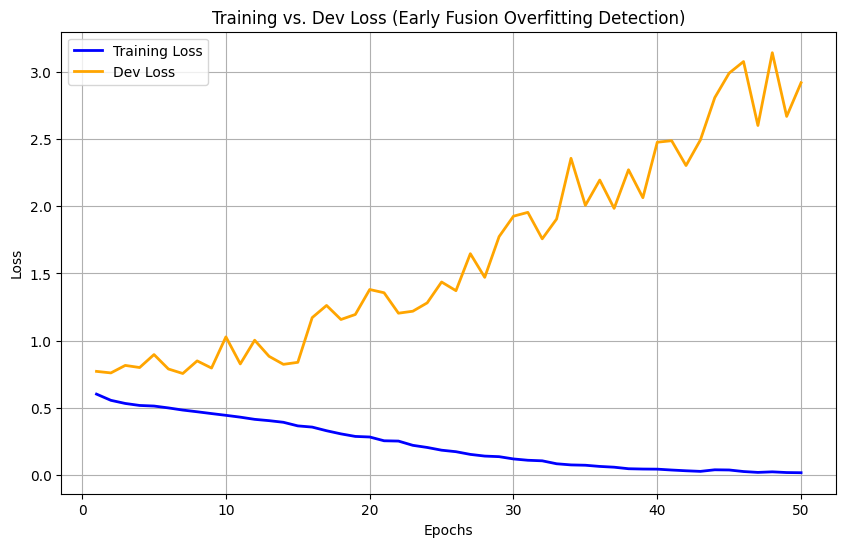

In [101]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import copy

# 1. Instantiate model, loss function, and optimizer
model = Classifier(input_dim=1280, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Concatenate image and text features into a single early-fusion tensor
X_fused_train = torch.cat([X_image['train'], X_text['train']], dim=1)
X_fused_dev = torch.cat([X_image['dev'], X_text['dev']], dim=1)

# 2. Setup your DataLoaders
# FIX: Pass the fused tensors here instead of X_image
train_dataset = TensorDataset(X_fused_train, y['train'].float().unsqueeze(1))
dev_dataset = TensorDataset(X_fused_dev, y['dev'].float().unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

# Lists to record loss histories for plotting
train_loss_history = []
dev_loss_history = []

# 3. Training and Evaluation Loop
num_epochs = 50  

# Setup your tracking variables before the loop
best_dev_loss = float('inf')
best_model_weights = None
checkpoint_path = "best_early_fusion_classifier_model.pt"

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    total_train_loss = train_loss / len(train_loader.dataset)
    train_loss_history.append(total_train_loss)
    
    # --- EVALUATION PHASE (ON DEV SET) ---
    model.eval()
    dev_loss = 0.0
    dev_preds = []
    dev_true = []
    
    with torch.no_grad():
        for batch_x, batch_y in dev_loader:
            logits = model(batch_x)
            
            loss = criterion(logits, batch_y)
            dev_loss += loss.item() * batch_x.size(0)
            
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).int()
            
            dev_preds.extend(preds.cpu().numpy())
            dev_true.extend(batch_y.cpu().numpy())

    total_dev_loss = dev_loss / len(dev_loader.dataset)
    dev_loss_history.append(total_dev_loss)
    
    # Calculate metrics
    acc = accuracy_score(dev_true, dev_preds)
    f1 = f1_score(dev_true, dev_preds, zero_division=0)
    
    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {total_train_loss:.4f} | Dev Loss: {total_dev_loss:.4f} | Dev F1: {f1:.4f}")

    if total_dev_loss < best_dev_loss:
        best_dev_loss = total_dev_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        print(f"  --> New best Dev Loss achieved ({best_dev_loss:.4f}). Saving checkpoint weights memory.")

if best_model_weights is not None:
    torch.save(best_model_weights, checkpoint_path)
    print(f"\n[SUCCESS] Best model weights saved to '{checkpoint_path}' with Dev Loss: {best_dev_loss:.4f}")

print(f"accuracy: {acc:.2f}, f1: {f1:.2f}")
    
# --- PLOTTING THE CURVES ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss', color='blue', lw=2)
plt.plot(range(1, num_epochs + 1), dev_loss_history, label='Dev Loss', color='orange', lw=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Dev Loss (Early Fusion Overfitting Detection)')
plt.legend()
plt.grid(True)
plt.show()


6.2 Simple late fusion (combine the predictions)
Use your already-trained text-only and image-only classifiers, and combine their predicted probabilities, for
example by averaging them:

In [102]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Initialize and load both pretrained models
text_model = Classifier(input_dim=768, hidden_dim=100) # Update dimensions if they differ
text_model.load_state_dict(torch.load("best__text_classifier_model.pt", weights_only=True))

image_model = Classifier(input_dim=512, hidden_dim=100)
image_model.load_state_dict(torch.load("best_image_classifier_model.pt", weights_only=True))

# 2. Put both models into evaluation mode
text_model.eval()
image_model.eval()

# 3. Extract your dev features and true labels
dev_text_X = X_text['dev']    # Assuming your text features match this key structure
dev_image_X = X_image['dev']  
dev_true_labels = y['dev'].cpu().numpy()

# 4. Compute combined probabilities without calculating gradients
with torch.no_grad():
    # Pass logits through sigmoid to get probabilities in range [0, 1]
    p_text = torch.sigmoid(text_model(dev_text_X))
    p_image = torch.sigmoid(image_model(dev_image_X))
    
    # Simple late fusion by averaging the two probability distributions
    p_late = (p_text + p_image) / 2.0
    
    # Convert averaged probabilities to binary class predictions (threshold 0.5)
    late_preds = (p_late >= 0.5).int().cpu().numpy()

# 5. Evaluate the final fused ensemble performance
ensemble_f1 = f1_score(dev_true_labels, late_preds, zero_division=0)
ensemble_acc = accuracy_score(dev_true_labels, late_preds)

print(f"--- Late Fusion Results ---")
print(f"Ensemble Accuracy: {ensemble_acc:.4f}")
print(f"Ensemble F1-Score: {ensemble_f1:.4f}")

--- Late Fusion Results ---
Ensemble Accuracy: 0.5804
Ensemble F1-Score: 0.4798


ARI 510
One design change. Propose and test one change to how the two modalities are combined, and
justify it. 

    For my design change I am going to use CLIP to encode both the text and the images together into a single vector space. I believe this is imperative to achieving good results in classifying an image and text pair. In our experiments thus far we have seen advancement in fusion models in accuracy when evaluating the dev set. The models are able to train longer without overfitting to the data in the early fusion model which means there are gains to be made in marrying the two before training, and the Late Fusion accuracy results indicate that the correct answer isn't just dominated by one part of the equation, both have a critical part to play in the correct classfication.

    CLIP will allow us to marry the two datasets together in common context. CLIP itself has two encoders, one that works with text and one that works with images, but ultimately they were trained together to perfectly align with each other. When first seeing CLIP I thought "well isn't that just early fusion?" and after reading a bit i started to develop a better conceptual understanding of why it may produce better results. In Early Fusion we are concatenating to different embeddings to each other from two different encoders, BERT, and ResNet. What we get is a feature set almost written in two different languages, one written in the language of understanding text, and one written in the language of understanding images. When the model trains on this data it doesn't have the best shot at marrying the two because they aren't "speaking the same language". It's like handing a student a text book where half of it is spanish and half is japanese and asking it to learn the subject thoroughly. Using CLIP is like bringing this information into a common language between the 2 before delivering it to the model. it'd be much easier for the student to learn the subject if the entire spanish/japanese text was converted to French first.

In [116]:
import os
import torch
import pandas as pd
from transformers import CLIPProcessor, CLIPModel
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Initialize CLIP processor and model
model_name = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(model_name)
clip_model = CLIPModel.from_pretrained(model_name).to(device).eval()


# 2. Robust Text Embedding Function (CLIP)
def embed_texts_clip(texts, batch_size=32):
    """List of strings -> tensor of shape [len(texts), 512]."""
    out = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        # Force convert all items to standard strings to protect against NaN/float values in pandas
        batch_texts = [str(t) for t in batch_texts]
        
        inputs = processor(text=batch_texts, padding=True, truncation=True,
                           max_length=77, return_tensors="pt").to(device)
        
        with torch.no_grad():
            # Get raw tensor output directly using the sub-module (cross-version safe)
            text_features = clip_model.text_model(**inputs, return_dict=False)[1]
            text_features = clip_model.text_projection(text_features)
            
            # Normalize embeddings
            text_features = text_features / text_features.norm(p=2, dim=-1, keepdim=True)
            out.append(text_features.cpu())
            
    return torch.cat(out)


# 3. Robust Image Embedding Function (CLIP)
def embed_images_clip(paths, batch_size=32):
    """List of image paths -> tensor of shape [len(paths), 512]."""
    out = []
    for i in range(0, len(paths), batch_size):
        # Open the image files using your verified df['path'] strings
        pil_images = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        inputs = processor(images=pil_images, return_tensors="pt").to(device)
        
        with torch.no_grad():
            # Get raw tensor output directly using the sub-module (cross-version safe)
            image_features = clip_model.vision_model(**inputs, return_dict=False)[1]
            image_features = clip_model.visual_projection(image_features)
            
            # Normalize embeddings
            image_features = image_features / image_features.norm(p=2, dim=-1, keepdim=True)
            out.append(image_features.cpu())
            
    return torch.cat(out)


# =====================================================================
# 4. MAP DATAFRAMES AND EXTRACT SPLITS
# =====================================================================

# Ensure the output directory exists
output_folder = "lab3_embeddings"
os.makedirs(output_folder, exist_ok=True)

# Map your real train, dev, and test DataFrames directly to the processor config
dataset_splits = {
    "train": train,
    "dev": dev,
    "test": test
}

for split_name, df in dataset_splits.items():
    print(f"\n--- Processing Split: [{split_name.upper()}] ({len(df)} samples) ---")
    
    # Extract lists straight from the DataFrame columns
    texts_list = df["text"].tolist()
    paths_list = df["path"].tolist()
    
    print(f"Extracting CLIP text embeddings...")
    x_txt = embed_texts_clip(texts_list, batch_size=32)
    
    print(f"Extracting CLIP image embeddings...")
    x_img = embed_images_clip(paths_list, batch_size=32)
    
    # Define file destinations
    image_save_path = os.path.join(output_folder, f"clip_image_{split_name}.pt")
    text_save_path = os.path.join(output_folder, f"clip_text_{split_name}.pt")
    
    # Save arrays to disk
    torch.save(x_img, image_save_path)
    torch.save(x_txt, text_save_path)
    
    print(f"[SUCCESS] Saved {split_name} tensors:\n -> {image_save_path}\n -> {text_save_path}")

print(f"\n[COMPLETE] All splits successfully stored inside '{output_folder}/'!")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 1853.06it/s, Materializing param=visual_projection.weight]                                
CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- Processing Split: [TRAIN] (8500 samples) ---
Extracting CLIP text embeddings...
Extracting CLIP image embeddings...
[SUCCESS] Saved train tensors:
 -> lab3_embeddings\clip_image_train.pt
 -> lab3_embeddings\clip_text_train.pt

--- Processing Split: [DEV] (500 samples) ---
Extracting CLIP text embeddings...
Extracting CLIP image embeddings...
[SUCCESS] Saved dev tensors:
 -> lab3_embeddings\clip_image_dev.pt
 -> lab3_embeddings\clip_text_dev.pt

--- Processing Split: [TEST] (1000 samples) ---
Extracting CLIP text embeddings...
Extracting CLIP image embeddings...
[SUCCESS] Saved test tensors:
 -> lab3_embeddings\clip_image_test.pt
 -> lab3_embeddings\clip_text_test.pt

[COMPLETE] All splits successfully stored inside 'lab3_embeddings/'!


Epoch 01/50 | Train Loss: 0.5723 | Dev Loss: 0.7179 | Dev F1: 0.3876
  --> New best Dev Loss achieved (0.7179). Saving checkpoint weights to memory.
Epoch 02/50 | Train Loss: 0.4941 | Dev Loss: 0.7655 | Dev F1: 0.3743
Epoch 03/50 | Train Loss: 0.4681 | Dev Loss: 0.7120 | Dev F1: 0.5075
  --> New best Dev Loss achieved (0.7120). Saving checkpoint weights to memory.
Epoch 04/50 | Train Loss: 0.4500 | Dev Loss: 0.7110 | Dev F1: 0.5174
  --> New best Dev Loss achieved (0.7110). Saving checkpoint weights to memory.
Epoch 05/50 | Train Loss: 0.4335 | Dev Loss: 0.7336 | Dev F1: 0.5026
Epoch 06/50 | Train Loss: 0.4178 | Dev Loss: 0.7592 | Dev F1: 0.4636
Epoch 07/50 | Train Loss: 0.4000 | Dev Loss: 0.7619 | Dev F1: 0.4948
Epoch 08/50 | Train Loss: 0.3836 | Dev Loss: 0.7338 | Dev F1: 0.5347
Epoch 09/50 | Train Loss: 0.3656 | Dev Loss: 0.7699 | Dev F1: 0.5141
Epoch 10/50 | Train Loss: 0.3489 | Dev Loss: 0.7912 | Dev F1: 0.4728
Epoch 11/50 | Train Loss: 0.3335 | Dev Loss: 0.7430 | Dev F1: 0.5409
E

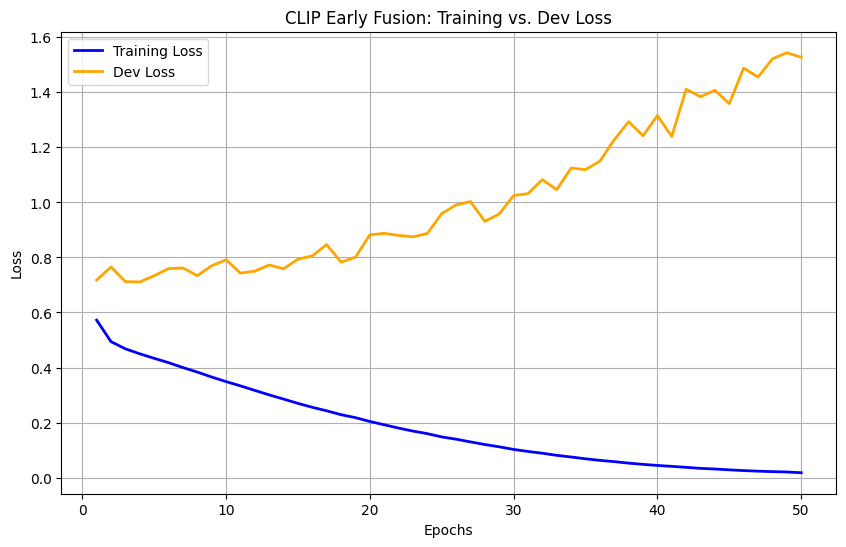

In [117]:
import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# 1. LOAD EMBEDDINGS FROM DISK AND PULL LABELS FROM DATAFRAMES
# ---------------------------------------------------------------------
output_folder = "lab3_embeddings"

# Load pre-extracted CLIP tensors
clip_img_train = torch.load(os.path.join(output_folder, "clip_image_train.pt"), weights_only=True)
clip_txt_train = torch.load(os.path.join(output_folder, "clip_text_train.pt"), weights_only=True)

clip_img_dev = torch.load(os.path.join(output_folder, "clip_image_dev.pt"), weights_only=True)
clip_txt_dev = torch.load(os.path.join(output_folder, "clip_text_dev.pt"), weights_only=True)

# Pull your ground truth classification labels directly from your loaded DataFrames
y_train = torch.tensor(train['label'].values).float().unsqueeze(1)
y_dev = torch.tensor(dev['label'].values).float().unsqueeze(1)

# Concatenate image (512) and text (512) features horizontally into an early-fusion matrix (1024)
X_fused_train = torch.cat([clip_img_train, clip_txt_train], dim=1)
X_fused_dev = torch.cat([clip_img_dev, clip_txt_dev], dim=1)

# ---------------------------------------------------------------------
# 2. INSTANTIATE MODEL, LOSS, AND DATALOADERS
# ---------------------------------------------------------------------
# FIX: input_dim is now 1024 (512 image + 512 text)
model = Classifier(input_dim=1024, hidden_dim=100)
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)

train_dataset = TensorDataset(X_fused_train, y_train)
dev_dataset = TensorDataset(X_fused_dev, y_dev)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)

train_loss_history = []
dev_loss_history = []

num_epochs = 50  
best_dev_loss = float('inf')
best_model_weights = None
checkpoint_path = "best_clip_early_fusion_model.pt"

# ---------------------------------------------------------------------
# 3. TRAINING AND EVALUATION LOOP
# ---------------------------------------------------------------------
for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    total_train_loss = train_loss / len(train_loader.dataset)
    train_loss_history.append(total_train_loss)
    
    # --- EVALUATION PHASE (ON DEV SET) ---
    model.eval()
    dev_loss = 0.0
    dev_preds = []
    dev_true = []
    
    with torch.no_grad():
        for batch_x, batch_y in dev_loader:
            logits = model(batch_x)
            
            loss = criterion(logits, batch_y)
            dev_loss += loss.item() * batch_x.size(0)
            
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).int()
            
            dev_preds.extend(preds.cpu().numpy())
            dev_true.extend(batch_y.cpu().numpy())

    total_dev_loss = dev_loss / len(dev_loader.dataset)
    dev_loss_history.append(total_dev_loss)
    
    # Calculate metrics
    acc = accuracy_score(dev_true, dev_preds)
    f1 = f1_score(dev_true, dev_preds, zero_division=0)
    
    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {total_train_loss:.4f} | Dev Loss: {total_dev_loss:.4f} | Dev F1: {f1:.4f}")

    if total_dev_loss < best_dev_loss:
        best_dev_loss = total_dev_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        print(f"  --> New best Dev Loss achieved ({best_dev_loss:.4f}). Saving checkpoint weights to memory.")

# Save the absolute best weights back out to disk
if best_model_weights is not None:
    torch.save(best_model_weights, checkpoint_path)
    print(f"\n[SUCCESS] Best CLIP model weights saved to '{checkpoint_path}' with Dev Loss: {best_dev_loss:.4f}")

print(f"Final Dev Accuracy: {acc:.2f}, Final Dev F1: {f1:.2f}")
    
# --- PLOTTING THE CURVES ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss', color='blue', lw=2)
plt.plot(range(1, num_epochs + 1), dev_loss_history, label='Dev Loss', color='orange', lw=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('CLIP Early Fusion: Training vs. Dev Loss')
plt.legend()
plt.grid(True)
plt.show()


    The Clip embeddings proved to be the best model overall on accuracy and holding off extreme overfitting for the longest period of time. It looks like it lasted almost 20 epochs before experiencing significant loss.

Part 4: Final Comparison
Once you have made all your choices on the dev set, evaluate all four models once on the test set: text-only,
image-only, early fusion, and late fusion.
Because most memes in the training set are not hateful, a model can learn to lean toward predicting
“not hateful,” and the dev and test sets don’t have the same balance as the training set. Report metrics,
but think about which ones you trust the most.

In [121]:
import os
import torch
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------------------
# 1. SETUP TENSORS & SOURCE DATA
# ---------------------------------------------------------------------
# Pull the true labels matching the full DataFrame (1000 samples)
test_true_labels_full = test['label'].values  

# Pull the original truncated feature tensors (815 samples)
orig_txt_test = X_text['test'].to(device)
orig_img_test = X_image['test'].to(device)
X_fused_orig_test = torch.cat([orig_img_test, orig_txt_test], dim=1)

# Align a subset of true labels to exactly match the 815-sample shape
test_true_labels_815 = test_true_labels_full[:orig_txt_test.size(0)]

# Extract fresh CLIP test tensors (1000 samples)
print(f"Extracting CLIP features matching full test DataFrame ({len(test)} samples)...")
test_texts = [str(t) for t in test["text"].tolist()]
test_paths = test["path"].tolist()

X_clip_img_test = embed_images_clip(test_paths, batch_size=32).to(device)
X_clip_txt_test = embed_texts_clip(test_texts, batch_size=32).to(device)
X_fused_clip_test = torch.cat([X_clip_img_test, X_clip_txt_test], dim=1)


# ---------------------------------------------------------------------
# 2. GENERAL STANDALONE EVALUATION HELPER
# ---------------------------------------------------------------------
def evaluate_standalone(model_path, input_dim, test_features, true_labels):
    """Loads a standalone checkpoint and generates a full metrics dict."""
    if not os.path.exists(model_path):
        print(f"⚠️ Warning: {model_path} not found. Skipping evaluation.")
        return None
        
    model = Classifier(input_dim=input_dim, hidden_dim=100).to(device)
    model.load_state_dict(torch.load(model_path, weights_only=True))
    model.eval()
    
    with torch.no_grad():
        logits = model(test_features)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).int().cpu().numpy()
        
    return {
        "Accuracy": accuracy_score(true_labels, preds),
        "Precision": precision_score(true_labels, preds, zero_division=0),
        "Recall": recall_score(true_labels, preds, zero_division=0),
        "F1-Score": f1_score(true_labels, preds, zero_division=0)
    }


# Dictionary to store performance results across all variants
all_model_metrics = {}

# ---------------------------------------------------------------------
# 2.5 ADD DUMMY MAJORITY BASELINE
# ---------------------------------------------------------------------
# Find the most frequent class label in the full test set
majority_class = np.bincount(test_true_labels_full).argmax()
# Generate predictions where every single sample gets the majority label
majority_preds = np.full_like(test_true_labels_full, fill_value=majority_class)

all_model_metrics["Dummy Majority Baseline"] = {
    "Accuracy": accuracy_score(test_true_labels_full, majority_preds),
    "Precision": precision_score(test_true_labels_full, majority_preds, zero_division=0),
    "Recall": recall_score(test_true_labels_full, majority_preds, zero_division=0),
    "F1-Score": f1_score(test_true_labels_full, majority_preds, zero_division=0)
}

# ---------------------------------------------------------------------
# 3. EVALUATE TARGET MODELS WITH CORRESPONDING DATA SHAPES
# ---------------------------------------------------------------------

# Model A: Original Image-Only Model (512 Dim, 815 Samples)
metrics_img = evaluate_standalone("best_image_classifier_model.pt", 512, orig_img_test, test_true_labels_815)
if metrics_img: 
    all_model_metrics["Image-Only (Original ResNet)"] = metrics_img

# Model B: Original Text-Only Model (768 Dim, 815 Samples)
metrics_txt = evaluate_standalone("best__text_classifier_model.pt", 768, orig_txt_test, test_true_labels_815)
if metrics_txt: 
    all_model_metrics["Text-Only (Original BERT)"] = metrics_txt

# Model C: Original Early Fusion Model (1280 Dim, 815 Samples)
metrics_ef_orig = evaluate_standalone("best_early_fusion_classifier_model.pt", 1280, X_fused_orig_test, test_true_labels_815)
if metrics_ef_orig: 
    all_model_metrics["Early Fusion (Original Space)"] = metrics_ef_orig

# Model D: CLIP Early Fusion Model (1024 Dim, 1000 Samples)
metrics_ef_clip = evaluate_standalone("best_clip_early_fusion_model.pt", 1024, X_fused_clip_test, test_true_labels_full)
if metrics_ef_clip: 
    all_model_metrics["Early Fusion (CLIP Space)"] = metrics_ef_clip

# ---------------------------------------------------------------------
# 4. EVALUATE LATE FUSION ENSEMBLE (Original Space, 815 Samples)
# ---------------------------------------------------------------------
if os.path.exists("best__text_classifier_model.pt") and os.path.exists("best_image_classifier_model.pt"):
    txt_model = Classifier(input_dim=768, hidden_dim=100).to(device)
    txt_model.load_state_dict(torch.load("best__text_classifier_model.pt", weights_only=True))
    txt_model.eval()
    
    img_model = Classifier(input_dim=512, hidden_dim=100).to(device)
    img_model.load_state_dict(torch.load("best_image_classifier_model.pt", weights_only=True))
    img_model.eval()
    
    with torch.no_grad():
        p_text = torch.sigmoid(txt_model(orig_txt_test))
        p_image = torch.sigmoid(img_model(orig_img_test))
        p_late = (p_text + p_image) / 2.0
        late_preds = (p_late >= 0.5).int().cpu().numpy()
        
    all_model_metrics["Late Fusion Ensemble (BERT + ResNet)"] = {
        "Accuracy": accuracy_score(test_true_labels_815, late_preds),
        "Precision": precision_score(test_true_labels_815, late_preds, zero_division=0),
        "Recall": recall_score(test_true_labels_815, late_preds, zero_division=0),
        "F1-Score": f1_score(test_true_labels_815, late_preds, zero_division=0)
    }


# ---------------------------------------------------------------------
# 5. PRINT COMPREHENSIVE PERFORMANCE SUMMARY TABLE
# ---------------------------------------------------------------------
print("\n" + "="*95)
print(f"{'MODEL VARIANT':<40} | {'ACCURACY':<10} | {'PRECISION':<10} | {'RECALL':<10} | {'F1-SCORE':<10}")
print("="*95)

for name, metrics in all_model_metrics.items():
    print(f"{name:<40} | "
          f"{metrics['Accuracy']:<10.4f} | "
          f"{metrics['Precision']:<10.4f} | "
          f"{metrics['Recall']:<10.4f} | "
          f"{metrics['F1-Score']:<10.4f}")
print("="*95)





Extracting CLIP features matching full test DataFrame (1000 samples)...

MODEL VARIANT                            | ACCURACY   | PRECISION  | RECALL     | F1-SCORE  
Dummy Majority Baseline                  | 0.5100     | 0.0000     | 0.0000     | 0.0000    
Image-Only (Original ResNet)             | 0.4908     | 0.4883     | 0.5136     | 0.5006    
Text-Only (Original BERT)                | 0.4847     | 0.4735     | 0.3309     | 0.3895    
Early Fusion (Original Space)            | 0.4834     | 0.4712     | 0.3235     | 0.3836    
Early Fusion (CLIP Space)                | 0.6330     | 0.6952     | 0.4469     | 0.5441    
Late Fusion Ensemble (BERT + ResNet)     | 0.5006     | 0.4964     | 0.3432     | 0.4058    


    It is aesthetically pleasing to se how my hypotheses have aligned with the experiments. When evaluating on the test set I believe the best metric to use is accuracy or to say out of all possible opportunities to guess correctly how often did it guess correctly. In this experiment there is no loss from incorrect guesses, you are simply just trying to get the most possible correct guesses. Because the test set is majority "not hateful" we can see the baseline model is the second most accurate model in the experiments. Just guessing not hateful puts it at %51 percent. The only model to beat it was early fusion CLIP in fact. Intuitively CLIP is my first choice when looking at conceptually which model would perform best. CLIP aims to embed both images and text in a common space, bringing them contextually together for the model to train on.